# 08 · What can I see from the Sardagna cable-car arrival?

**Reading Trento's terrain, vegetation and surface temperature**

A visitor steps out at the Sardagna cable-car arrival and asks: **“What can I see from here?”**

We will use that familiar question to learn how raster data work. A street map can help name places. A terrain raster can help predict which parts of the landscape are hidden or exposed from a chosen position. Satellite bands can help us investigate the vegetation and surface temperatures of the city below. These datasets answer different parts of the visitor's question.

Our observation point is the position supplied by the instructor: **latitude 46.065843, longitude 11.103062**. We will ask:

1. Where is this point within the surrounding terrain?
2. Which surface cells could be visible from it, according to an elevation model?
3. Which areas of the city show a vegetation signal?
4. What did thermal observations measure on three summer dates in 2024–2026?

We will inspect what a pixel means before calculating. We will also separate a modelled viewshed from a verified panorama, and a dated satellite observation from today's conditions.

Choose YEAR below for the satellite calculations. The final maps compare the three selected acquisitions using fixed legends and an OSM background.

### Course files and original measurements

The satellite crops and metadata are distributed in the [course GitHub data folder](https://github.com/napo/geospatial-data-science-2026/tree/main/data), under `raster_2024_2026/`. GitHub is the teaching distribution point; the original sources remain Copernicus Sentinel-2 and NASA/USGS Landsat, accessed through Planetary Computer.

**Until the new folder is uploaded to GitHub**, extract the supplied `08_raster_data_2024_2026.zip` into the notebook working directory. It creates `data/raster_2024_2026/`. The code uses those local files when present and otherwise downloads them via HTTP from GitHub:

```python
import zipfile
with zipfile.ZipFile("08_raster_data_2024_2026.zip") as archive:
    archive.extractall(".")
```

Each year's folder contains original-value band crops, original scene metadata, Sentinel calibration read from its product XML, source records and the derived maps. The main lesson recalculates NDVI and temperature rather than treating the derived rasters as unexplained inputs.

**Two different Landsat quality assets:** `qa_pixel` contains bit flags for clouds and related pixel conditions. `qa` is **ST_QA**, an uncertainty estimate for surface temperature. It must not be interpreted as the QA_PIXEL bit mask. Both are named explicitly in the new files.

The terrain tile still downloads directly from Mapterhorn. WhiteboxTools downloads its executable on first use.


In [1]:
%pip install -q requests numpy pandas matplotlib rasterio pillow mercantile geopandas folium mapclassify whitebox

In [2]:
from pathlib import Path
from io import BytesIO
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import mercantile
import rasterio
from rasterio.plot import show
from rasterio.transform import from_bounds
from rasterio.warp import calculate_default_transform, reproject, Resampling, transform_bounds
import geopandas as gpd
import folium
from IPython.display import display

DATA = Path("data")
DATA.mkdir(exist_ok=True)

# Direct HTTP links return file bytes, rather than a GitHub preview page.
DATA_BASE_URL = "https://raw.githubusercontent.com/napo/geospatial-data-science-2026/main/data/"

### Three observations of the city below

Our viewpoint is fixed, but vegetation and surface temperature change with time. Start with YEAR=2024 and inspect the acquisition table. The selected optical/thermal pairs are from **31 July 2024**, **12 August 2025** and **15 August 2026**. Read the metadata for their exact acquisition times.

These are summer snapshots, not annual averages or today's view. Change YEAR and rerun the satellite sections to repeat the calculations for another observation.

In [3]:
YEAR = 2024  # Choose 2024, 2025 or 2026.

catalog_path = DATA / "raster_2024_2026/catalog.json"
if not catalog_path.exists():
    url = DATA_BASE_URL + "raster_2024_2026/catalog.json"
    print("Downloading:", url)
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    catalog_path.parent.mkdir(parents=True, exist_ok=True)
    catalog_path.write_bytes(response.content)
annual_catalog = json.loads(catalog_path.read_text())
display(pd.DataFrame(annual_catalog["records"])[[
    "year", "sentinel_date", "landsat_date", "date_gap_days",
    "sentinel_local_retained_fraction", "landsat_local_retained_fraction"]])
selected_year = next(row for row in annual_catalog["records"] if row["year"] == YEAR)
SENTINEL_DATE = selected_year["sentinel_date"]
LANDSAT_DATE = selected_year["landsat_date"]
YEAR_DATA = DATA / selected_year["files_folder"]
YEAR_DATA.mkdir(parents=True, exist_ok=True)
YEAR_BASE_URL = DATA_BASE_URL + selected_year["files_folder"] + "/"
print("Selected:", YEAR, SENTINEL_DATE, LANDSAT_DATE)

Downloading: https://raw.githubusercontent.com/napo/geospatial-data-science-2026/main/data/raster_2024_2026/catalog.json


,year,sentinel_date,landsat_date,date_gap_days,sentinel_local_retained_fraction,landsat_local_retained_fraction
0,2024,2024-07-31,2024-07-31,0,0.999129,1.0
1,2025,2025-08-12,2025-08-12,0,0.998511,1.0
2,2026,2026-08-15,2026-08-15,0,0.997783,1.0


Selected: 2024 2024-07-31 2024-07-31


## Before the viewpoint: what is a raster?

In previous lessons, a row could describe a pharmacy point, an administrative polygon or a network edge. A raster organises observations on a **regular grid of rows and columns**.

Each cell stores a value for a spatial support. That value might represent height, reflectance, temperature, a category or missing data. It does not automatically represent the visible colour of that place.

| Component | Question to ask |
|---|---|
| Rows and columns | Where is this value in the array? |
| Band | Which variable or wavelength is stored? |
| Value and units | Is this height, reflectance, a stored DN or a class code? |
| Transform and CRS | Where is the cell in geographic space? |
| Cell spacing | How far apart are grid samples in the declared CRS? |
| Spatial support / source resolution | What area and detail does the sensor or model actually represent? |
| NoData and quality flags | Where is there no usable measurement? |
| Acquisition and processing | When and how was the value produced? |

A single-band height raster can be displayed in many colours. A multispectral acquisition can store several bands in separate files, as in our Sentinel-2 example. **The number of display colours is not the number of measured variables.**

With NumPy we can calculate on the array. With Rasterio we also retain where its cells belong. The first task is to connect those two views of the same data.


# Part A · Build a model of the view from Sardagna

The visitor is looking towards Trento. Before calculating what might be visible, we need the elevations of the observer's location **and the terrain being viewed**. A raster containing only the station would not answer the question.

Open [Mapterhorn](https://mapterhorn.com/) and locate the area. The website can render terrain in 3D, but the data we download are **Terrarium-encoded RGB elevation tiles**, not a 3D mesh.

We will combine four adjacent tiles into one elevation mosaic covering the arrival point and a wider part of Trento. Each source tile is 512 × 512 pixels. Its RGB values encode heights rather than the visible colours of the landscape.

[Data access](https://mapterhorn.com/data-access/) · [Coverage](https://mapterhorn.com/coverage/) · [Regional source attribution](https://mapterhorn.com/attribution/).

**Before running:** does the regional source describe bare earth or a surface including objects? Which obstacles could that model represent? Source resolution, grid sampling and elevation accuracy are different properties.

## 1. Download enough terrain to answer the question

Set the observer to **longitude 11.103062, latitude 46.065843**. Notice the order: the coordinates were supplied as latitude/longitude, while point construction uses longitude/latitude.

At zoom 13, find the tile containing the observer. Also obtain the tile north of it, the tile east of it and the northeastern tile. This **2 × 2 mosaic** extends towards the city rather than stopping at the edge of the observer's tile.

In XYZ addressing, x increases eastwards and y increases southwards. We keep the order northwestern/northeastern on the first row, then southwestern/southeastern on the second.

The mosaic gives us a larger extent at the same sampling. It does not create new source detail. Its outer edges remain the limits of our calculation.

**Colab AI prompt:** Using the supplied observer coordinates and zoom 13, construct a 2×2 tile grid covering the observer tile, north, east and northeast. Print download URLs and geographic bounds, retain the original Mapterhorn WebP files and inspect each image. Preserve the spatial ordering.

Tile: Tile(x=4348, y=2911, z=13) bounds: LngLatBbox(west=11.07421875, south=46.07323062540836, east=11.1181640625, north=46.10370875598026)
Download: https://tiles.mapterhorn.com/13/4348/2911.webp
Image size: (512, 512)


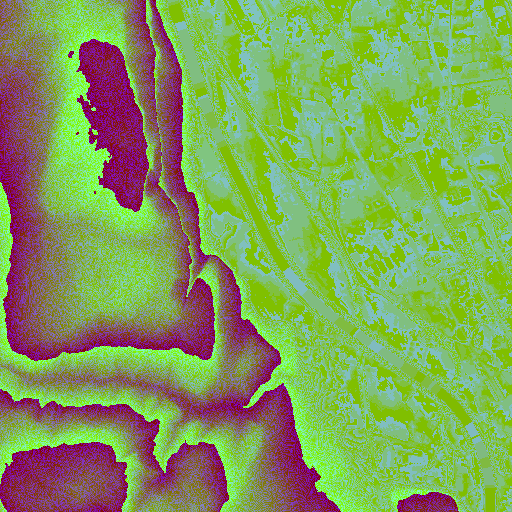

Tile: Tile(x=4349, y=2911, z=13) bounds: LngLatBbox(west=11.1181640625, south=46.07323062540836, east=11.162109375, north=46.10370875598026)
Download: https://tiles.mapterhorn.com/13/4349/2911.webp
Image size: (512, 512)


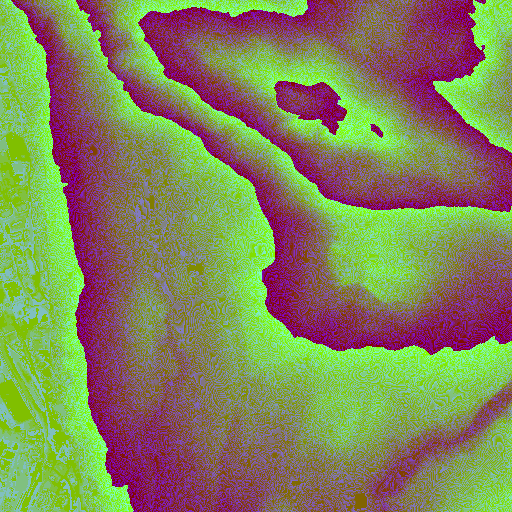

Tile: Tile(x=4348, y=2912, z=13) bounds: LngLatBbox(west=11.07421875, south=46.042735653846506, east=11.1181640625, north=46.07323062540836)
Download: https://tiles.mapterhorn.com/13/4348/2912.webp
Image size: (512, 512)


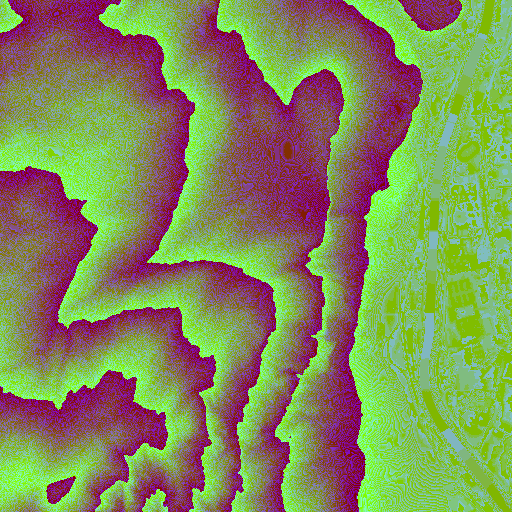

Tile: Tile(x=4349, y=2912, z=13) bounds: LngLatBbox(west=11.1181640625, south=46.042735653846506, east=11.162109375, north=46.07323062540836)
Download: https://tiles.mapterhorn.com/13/4349/2912.webp
Image size: (512, 512)


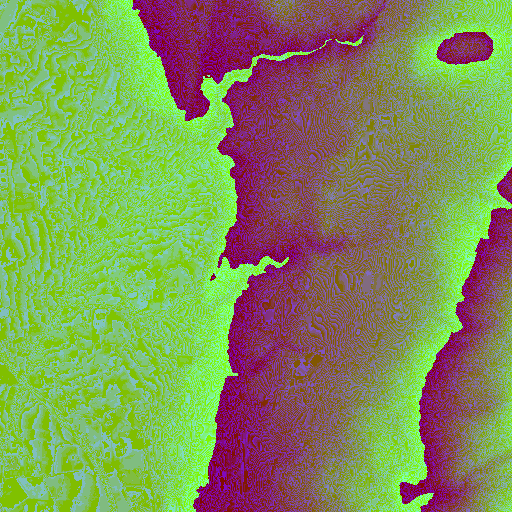

In [4]:
# Coordinates supplied for the Sardagna cable-car arrival: longitude, latitude.
observer_lon, observer_lat = 11.103062, 46.065843
zoom = 13
tile = mercantile.tile(observer_lon, observer_lat, zoom)
tile_grid = [
    [mercantile.Tile(tile.x, tile.y - 1, tile.z), mercantile.Tile(tile.x + 1, tile.y - 1, tile.z)],
    [tile, mercantile.Tile(tile.x + 1, tile.y, tile.z)],
]

tile_images = {}
for tile_row in tile_grid:
    for current_tile in tile_row:
        tile_url = f"https://tiles.mapterhorn.com/{current_tile.z}/{current_tile.x}/{current_tile.y}.webp"
        print("Tile:", current_tile, "bounds:", mercantile.bounds(current_tile))
        print("Download:", tile_url)
        response = requests.get(tile_url, timeout=60)
        response.raise_for_status()
        filename = f"mapterhorn_{current_tile.z}_{current_tile.x}_{current_tile.y}.webp"
        (DATA / filename).write_bytes(response.content)
        tile_images[current_tile] = Image.open(BytesIO(response.content))
        print("Image size:", tile_images[current_tile].size)
        display(tile_images[current_tile])

## 2. Read heights, not landscape colours

The tile's green or blue appearance does not tell us whether we are looking at trees or water. These channels store an encoded height:

**height in metres = R × 256 + G + B / 256 − 32768**

Decode each tile into floating-point elevations. Join the two columns with `np.hstack()` and the two rows with `np.vstack()`. The mosaic has **1,024 rows and 1,024 columns**; no averaging or resampling is needed at the aligned tile joins.

Inspect the range of heights. Can you recognise the valley and the higher terrain around Sardagna? Fractional storage precision is not a guarantee of measurement accuracy.

**Colab AI prompt:** Decode Terrarium RGB values into float32 elevations, preserve transparency as NoData, join the numeric tiles in their 2×2 geographic order and display the mosaic. Print its shape and height range.

Mosaic dimensions: (1024, 1024)
Elevation range (m): 182.0 1580.25


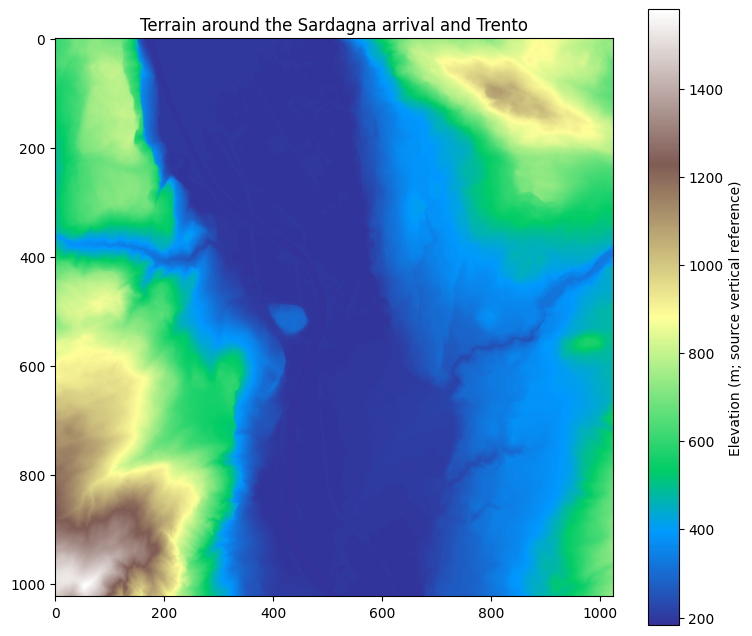

In [5]:
elevation_rows = []
for tile_row in tile_grid:
    row_parts = []
    for current_tile in tile_row:
        tile_image = tile_images[current_tile]
        rgb = np.asarray(tile_image.convert("RGB"), dtype="float32")
        red, green, blue = rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2]
        tile_elevation = red * 256 + green + blue / 256 - 32768
        if "A" in tile_image.getbands():
            tile_elevation[np.asarray(tile_image.getchannel("A")) == 0] = np.nan
        row_parts.append(tile_elevation)
    # Join west/east tiles first, then join the north/south rows.
    elevation_rows.append(np.hstack(row_parts))
elevation = np.vstack(elevation_rows)
print("Mosaic dimensions:", elevation.shape)
print("Elevation range (m):", np.nanmin(elevation), np.nanmax(elevation))
plt.figure(figsize=(9, 8))
plt.imshow(elevation, cmap="terrain")
plt.colorbar(label="Elevation (m; source vertical reference)")
plt.title("Terrain around the Sardagna arrival and Trento")
plt.show()

### What does one cell tell the visitor?

Before interpreting the coloured hills, read a 5×5 window of actual source heights. A row/column address gives a place in the array; it does not yet identify a place in Trento.

Compare nearby values. The coloured image is one representation of this numeric surface. Where values are missing, there is no elevation measurement to use.

In [6]:
# Inspect actual source values rather than generating an illustrative grid.
print("Array dimensions (rows, columns):", elevation.shape)
print("Numeric type:", elevation.dtype)
print("Missing cells:", np.count_nonzero(~np.isfinite(elevation)))
height_window = pd.DataFrame(
    elevation[250:255, 250:255],
    index=range(250, 255), columns=range(250, 255),
)
height_window.index.name = "row"
height_window.columns.name = "column"
display(height_window.round(2))

Array dimensions (rows, columns): (1024, 1024)
Numeric type: float32
Missing cells: 0


column,250,251,252,253,254
row,,,,,
250,193.0,193.0,193.0,193.0,193.00
251,193.0,193.0,193.0,193.0,193.00
252,193.0,193.0,193.0,193.0,193.00
253,193.0,193.0,193.0,193.0,192.75
254,193.0,193.0,193.0,193.0,192.75


## 3. Put the whole mosaic in the right place

We now attach a CRS and a transform to the combined numeric grid. The bounds must cover all four tiles. If we used the bounds of just one tile, we would squeeze the mosaic into the wrong geographic area.

Write a Web Mercator GeoTIFF containing heights, transform, CRS and NoData. This preserves more than a screenshot of the panorama or of the coloured elevation map.

**Colab AI prompt:** Georeference the 2×2 mosaic using its northwestern and southeastern outer bounds. Write an EPSG:3857 float32 GeoTIFF with -9999 NoData and inspect its extent, cell spacing and values.

CRS: EPSG:3857 Spacing: (9.554628535646998, 9.55462853564677) NoData: -9999.0
Mosaic bounds: BoundingBox(left=1232776.3921833225, bottom=5787200.285527265, right=1242560.331803825, top=5796984.225147767)


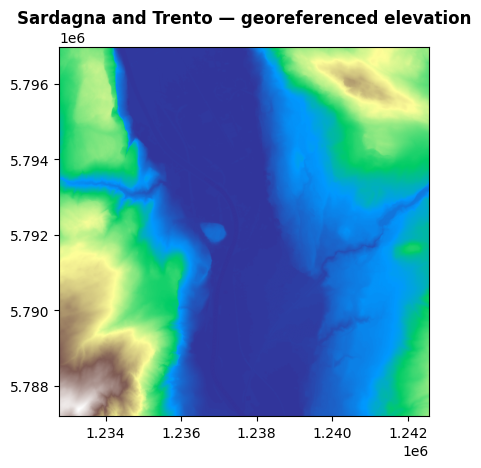

In [7]:
northwest_bounds = mercantile.xy_bounds(tile_grid[0][0])
southeast_bounds = mercantile.xy_bounds(tile_grid[1][1])
transform = from_bounds(
    northwest_bounds.left, southeast_bounds.bottom, southeast_bounds.right, northwest_bounds.top,
    elevation.shape[1], elevation.shape[0],
)
dem_web_path = DATA / "mapterhorn_mosaic_3857.tif"
with rasterio.open(dem_web_path, "w", driver="GTiff", height=elevation.shape[0],
                   width=elevation.shape[1], count=1, dtype="float32", crs="EPSG:3857",
                   transform=transform, nodata=-9999, compress="deflate") as dst:
    dst.write(np.where(np.isfinite(elevation), elevation, -9999).astype("float32"), 1)
    dst.update_tags(source="Mapterhorn Terrarium RGB tiles", operation="2x2 decoded mosaic, no resampling at joins")
with rasterio.open(dem_web_path) as src:
    print("CRS:", src.crs, "Spacing:", src.res, "NoData:", src.nodata)
    print("Mosaic bounds:", src.bounds)
    show(src, cmap="terrain", title="Sardagna and Trento — georeferenced elevation")

### Connect an array address to a place

The cell at row 250, column 250 has a value and a position. The transform locates its centre; the CRS explains the coordinates' reference system. These projected coordinates are not longitude and latitude.

We can now relate one entry in our array to the map, rather than merely displaying a rectangular image.


In [8]:
with rasterio.open(dem_web_path) as src:
    row, column = 250, 250
    x, y = src.xy(row, column)
    print("Row and column:", row, column)
    print("Cell-centre coordinates:", x, y)
    print("Coordinate reference:", src.crs)
    print("Cell value, metres:", src.read(1)[row, column])
    print("Number of bands:", src.count)

Row and column: 250 250
Cell-centre coordinates: 1235169.826631502 5794590.790699587
Coordinate reference: EPSG:3857
Cell value, metres: 193.0
Number of bands: 1


### A web map grid is not automatically the right analysis grid

We have located the cells, but we are about to compare horizontal distances with vertical heights. Web Mercator spacing changes in ground meaning with latitude. For this small Trento study area, we will use UTM zone 32N and a 10 m output grid.

This is **resampling**, not a new survey. A 10 m output cell does not prove 10 m source accuracy.

This also explains the difference between distribution formats. A GeoTIFF holds numeric pixels and their geographic reference. A **COG** adds an organisation suitable for efficient remote window reads. **PMTiles** packages addressed web tiles. An ordinary GeoTIFF is not automatically cloud optimized.

## 4. Prepare a local terrain grid

Our calculation will compare horizontal distances and heights around the Sardagna arrival. Reproject the mosaic into **UTM 32N, EPSG:32632**, using a 10 m output grid.

Bilinear interpolation suits this continuous elevation surface. Later we will use nearest-neighbour for categories, where averaging class codes would have no meaning.

Inspect the new grid. We have changed its representation, not conducted a new survey. A 10 m output spacing does not imply 10 m source accuracy.

**Colab AI prompt:** Reproject the elevation mosaic to EPSG:32632 at 10 m spacing with bilinear interpolation, preserving NoData. Inspect the resulting shape, CRS, spacing and valid cells before calculating visibility.

In [9]:
dem_path = DATA / "mapterhorn_mosaic_32632.tif"
with rasterio.open(dem_web_path) as src:
    utm_transform, width, height = calculate_default_transform(
        src.crs, "EPSG:32632", src.width, src.height, *src.bounds, resolution=10)
    profile = src.profile.copy()
    profile.update(crs="EPSG:32632", transform=utm_transform, width=width, height=height)
    with rasterio.open(dem_path, "w", **profile) as dst:
        reproject(source=rasterio.band(src, 1), destination=rasterio.band(dst, 1),
                  src_transform=src.transform, src_crs=src.crs,
                  dst_transform=utm_transform, dst_crs="EPSG:32632",
                  src_nodata=-9999, dst_nodata=-9999, resampling=Resampling.bilinear)
with rasterio.open(dem_path) as src:
    print(src.crs, src.shape, src.res, src.nodata)
    dem = src.read(1, masked=True)
    print("Valid cells:", dem.count())

EPSG:32632 (696, 699) (10.0, 10.0) -9999.0
Valid cells: 460761


### See a numeric raster over OSM

We now connect the raster calculation to a familiar street map. The following reusable display function does four things: reprojects onto a Web Mercator display grid, converts values to colours using a fixed scale, makes NoData transparent, and positions that rendering over OSM.

It does not change the saved analytical GeoTIFF. Reuse it for terrain, visibility, NDVI and temperature; keep each variable's units and legend explicit. The basemap is grayscale with 140% contrast, while the raster stays in colour.


In [10]:
from matplotlib import colormaps
from matplotlib.colors import Normalize
from branca.colormap import LinearColormap

def add_raster_on_osm(path, name, cmap, vmin, vmax, legend_title, m=None,
                      show_layer=True, year_choice=False):
    with rasterio.open(path) as src:
        transform, width, height = calculate_default_transform(
            src.crs, "EPSG:3857", src.width, src.height, *src.bounds)
        values = np.full((height, width), np.nan, dtype="float32")
        reproject(source=rasterio.band(src, 1), destination=values,
                  src_transform=src.transform, src_crs=src.crs,
                  dst_transform=transform, dst_crs="EPSG:3857",
                  src_nodata=src.nodata, dst_nodata=np.nan,
                  resampling=Resampling.nearest)
    bounds = rasterio.transform.array_bounds(height, width, transform)
    west, south, east, north = transform_bounds("EPSG:3857", "EPSG:4326", *bounds)
    rgba = colormaps[cmap](Normalize(vmin, vmax, clip=True)(values))
    rgba[~np.isfinite(values), 3] = 0
    if m is None:
        m = folium.Map(location=[(south+north)/2, (west+east)/2], tiles=None)
        # Keep OSM visible independently of the radio choices for annual rasters.
        folium.TileLayer("OpenStreetMap.HOT", control=False).add_to(m)
        m.get_root().header.add_child(folium.Element("""
        <style>.leaflet-tile-pane {filter: grayscale(100%) contrast(140%);}</style>
        """))
        legend = LinearColormap([colormaps[cmap](x) for x in np.linspace(0, 1, 8)],
                                vmin=vmin, vmax=vmax, caption=legend_title)
        legend.add_to(m)
        m.fit_bounds([[south, west], [north, east]])
    folium.raster_layers.ImageOverlay(
        rgba, bounds=[[south, west], [north, east]], opacity=0.40,
        name=name, show=show_layer, overlay=not year_choice).add_to(m)
    return m


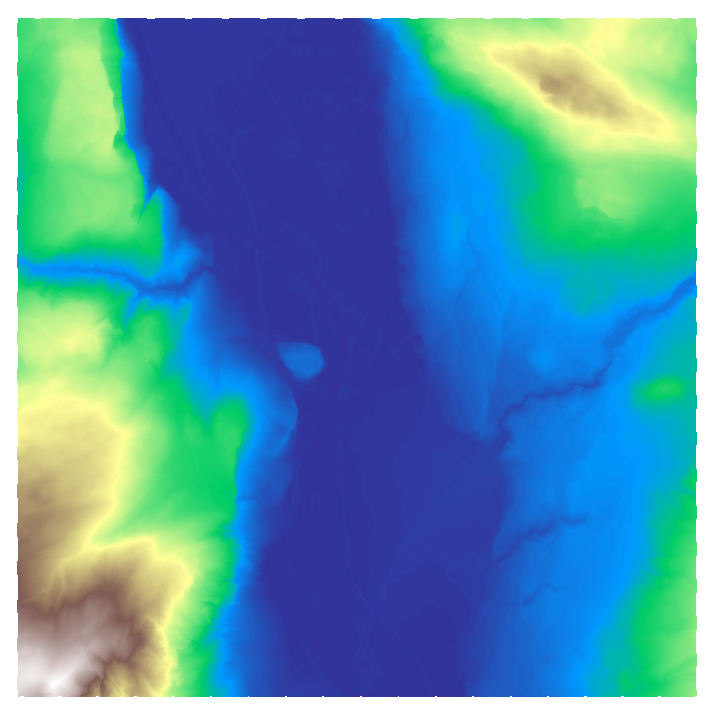

In [11]:
terrain_map = add_raster_on_osm(
    dem_path, "Elevation surface", "terrain", float(dem.min()), float(dem.max()), "Elevation (m)")
folium.Marker([observer_lat, observer_lon], tooltip="Observer: Sardagna cable-car arrival").add_to(terrain_map)
display(terrain_map)
terrain_map.save("sardagna_terrain_osm.html")

## 5. Place the visitor at the arrival point

Show the supplied position on OSM and sample the surface height at that location. We need to know where the observer stands relative to the model, not merely how high the hill appears on a map.

Use **1.7 m above the modelled surface** as the first observer-height assumption. This is different from altitude above sea level. The actual standing level, station structures and surrounding vegetation need field verification before claiming a precise real-world panorama.

**Colab AI prompt:** Create the observation point at longitude 11.103062, latitude 46.065843, show it on HOT OSM, project it to UTM 32N and sample its elevation from the mosaic. Write the station shapefile required by WhiteboxTools.

In [12]:
observer = gpd.GeoDataFrame({"name": ["Sardagna cable-car arrival"]},
    geometry=gpd.points_from_xy([observer_lon], [observer_lat]), crs=4326)
display(observer.explore(tiles="OpenStreetMap.HOT", color="red"))
observer_m = observer.to_crs(32632)
observer_path = DATA / "observer.shp"
observer_m.to_file(observer_path)
with rasterio.open(dem_path) as src:
    point = observer_m.geometry.iloc[0]
    observer_elevation = next(src.sample([(point.x, point.y)], masked=True))[0]
print("Surface elevation at observer (m):", observer_elevation)

Surface elevation at observer (m): 568.2262


## 6. Which parts of the modelled landscape could the visitor see?

Run a **viewshed** from the arrival point. The algorithm checks whether the modelled surface obstructs lines of sight from the observer to other surface cells.

For one observer, read 1 as visible and 0 as not visible **according to this model**. NoData means the calculation lacks a usable surface value. Put the result over OSM so we can relate the predicted pattern to named places.

The map predicts visibility of surface cells; it does not by itself identify every building in a photograph. A building, roof or tower may differ from the modelled terrain height. Trees, structures, haze and the actual viewing position can also affect a visitor's view.

**Colab AI prompt:** Calculate WhiteboxTools Viewshed for the arrival point with observer height 1.7 m. Inspect 0,1 and NoData, then display the result above OSM. Explain what the model can and cannot establish about recognisable places.

Decompressing WhiteboxTools_linux_musl.zip ...
WhiteboxTools package directory: /usr/local/lib/python3.13/dist-packages/whitebox
WhiteboxTools v2.4.0 (c) Dr. John Lindsay 2017-2023

WhiteboxTools is an advanced geospatial data analysis platform developed at
the University of Guelph's Geomorphometry and Hydrogeomatics Research 
Group (GHRG). See www.whiteboxgeo.com for more details.

Output values: [0. 1.]


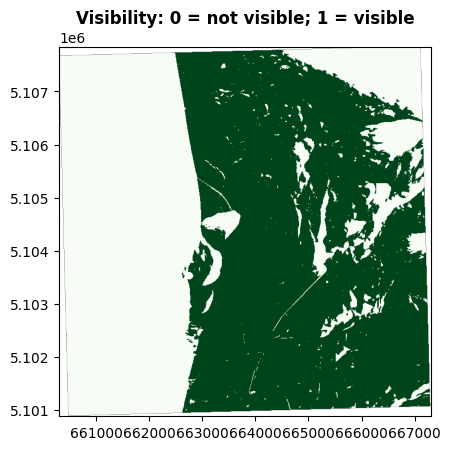

In [13]:
from whitebox.whitebox_tools import WhiteboxTools
wbt = WhiteboxTools()
wbt.set_working_dir(str(DATA.resolve()))
wbt.set_verbose_mode(False)
print(wbt.version())
viewshed_path = DATA / "viewshed_1_7m.tif"
result = wbt.viewshed(dem=str(dem_path.resolve()), stations=str(observer_path.resolve()),
                     output=str(viewshed_path.resolve()), height=1.7)
if result != 0 or not viewshed_path.exists():
    raise RuntimeError("Viewshed did not complete; inspect Whitebox output.")
with rasterio.open(viewshed_path) as src:
    visibility = src.read(1, masked=True)
    print("Output values:", np.unique(visibility.compressed()))
    show(src, cmap="Greens", vmin=0, vmax=1, title="Visibility: 0 = not visible; 1 = visible")


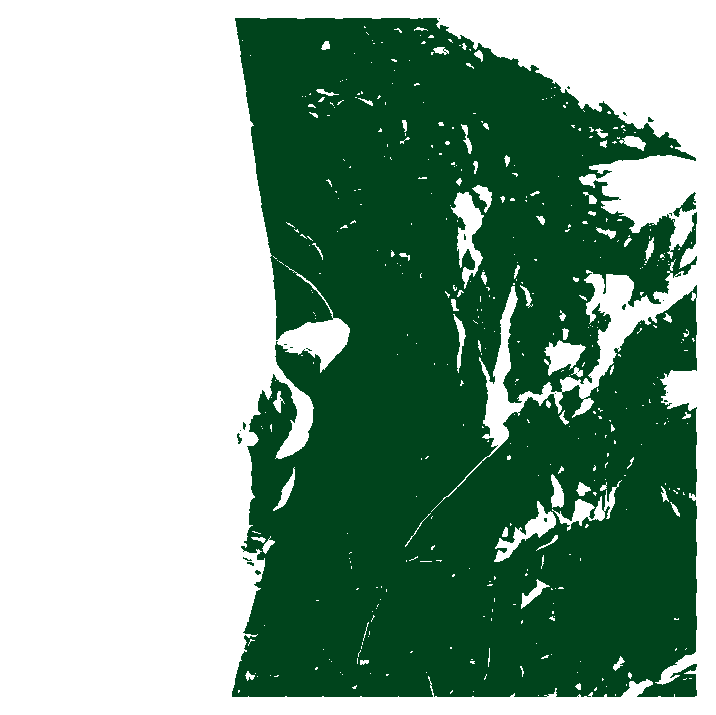

In [31]:
# Overlay the viewshed raster on the OSM basemap.
# Values: 0 = not visible, 1 = visible; NoData remains transparent.
viewshed_map = add_raster_on_osm(
    path=viewshed_path,
    name="Viewshed from the Sardagna cable-car arrival",
    cmap="Greens",
    vmin=0,
    vmax=1,
    legend_title="Modelled visibility: 0 = not visible; 1 = visible",
)

# Set the raster opacity: 0 = transparent, 1 = opaque.
for layer in viewshed_map._children.values():
    if isinstance(layer, folium.raster_layers.ImageOverlay):
        layer.options["opacity"] = 0.5

# Mark the observer's position.
folium.Marker(
    location=[observer_lat, observer_lon],
    tooltip="Sardagna cable-car arrival",
).add_to(viewshed_map)

# Allow the raster overlay to be switched on and off.
folium.LayerControl(collapsed=False).add_to(viewshed_map)

display(viewshed_map)

## 7. Does our answer depend on observer height?

Keep the surface and coordinates fixed, but rerun the viewshed with a hypothetical height of **10 m**. This is a sensitivity experiment, not a description of the visitor's actual position.

Compare the two maps and the fraction of valid cells classified as visible. Which boundaries move? Which remain constrained by the terrain?

The fraction describes only this fixed mosaic. Enlarging its extent changes the denominator and may change the fraction even if visibility at a particular place stays the same.

**Colab AI prompt:** Compare 1.7 m and 10 m observer heights from the same Sardagna point. Use the same elevation raster and valid-cell extent, report visible fractions and show the two viewsheds as selectable layers over OSM.

In [32]:
higher_path = DATA / "viewshed_10m.tif"
result = wbt.viewshed(dem=str(dem_path.resolve()), stations=str(observer_path.resolve()),
                     output=str(higher_path.resolve()), height=10)
if result != 0 or not higher_path.exists():
    raise RuntimeError("Second viewshed did not complete.")
visibility_summary = []
for observer_height, path in [(1.7, viewshed_path), (10, higher_path)]:
    with rasterio.open(path) as src:
        values = src.read(1, masked=True)
        # Keep only cells supported by both the terrain and the output.
        valid = ~np.ma.getmaskarray(values) & ~np.ma.getmaskarray(dem)
        visible_fraction = np.count_nonzero((values.data > 0) & valid) / np.count_nonzero(valid)
        visibility_summary.append({"observer_height_m": observer_height,
                                   "visible_fraction_in_valid_extent": visible_fraction})
display(pd.DataFrame(visibility_summary))

,observer_height_m,visible_fraction_in_valid_extent
0,1.7,0.543596
1,10.0,0.577907



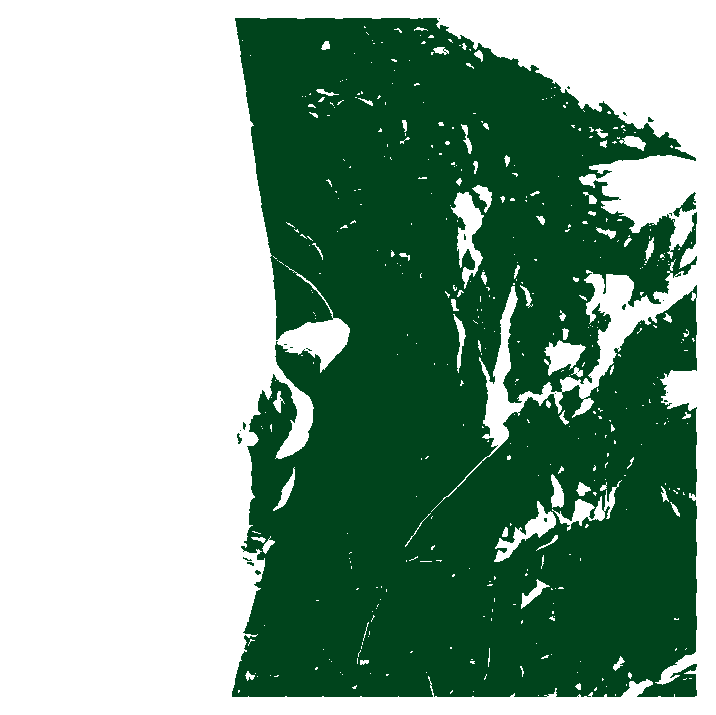
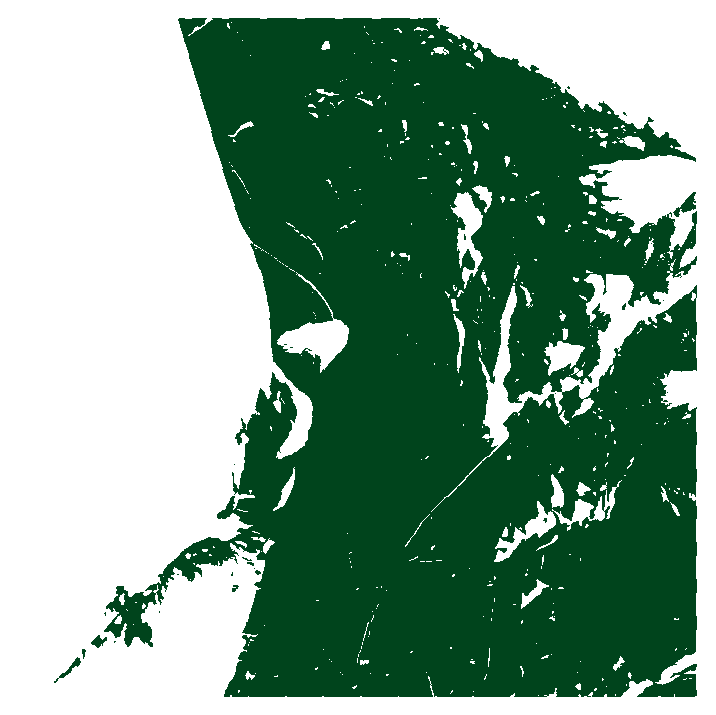

In [15]:
visibility_map = add_raster_on_osm(
    viewshed_path, "Observer height 1.7 m", "Greens", 0, 1,
    "Viewshed: 0 not visible; 1 visible", year_choice=True)
add_raster_on_osm(higher_path, "Observer height 10 m", "Greens", 0, 1,
                  "Viewshed", m=visibility_map, show_layer=False, year_choice=True)
folium.Marker([observer_lat, observer_lon], tooltip="Observer").add_to(visibility_map)
folium.LayerControl(collapsed=False).add_to(visibility_map)
display(visibility_map)
visibility_map.save("sardagna_viewshed_osm.html")

### Give the visitor a first answer

We can now point to parts of the **modelled surface** that are predicted to be visible from the supplied arrival point. Use the OSM context to locate them, and explain one area hidden behind terrain.

To identify a particular landmark rigorously, obtain its position and relevant height and compare those with the model. The viewshed alone is not a labelled panorama or a field validation.

We started with a web tile service and had to decide how to decode, join, locate and resample its values. Those decisions are part of answering the question.

Now imagine the visitor points towards green-looking patches in the city. The elevation model cannot tell us what those patches are. We need a different observation.

# Part B · What are the green areas down there?

From the arrival point, the visitor notices wooded slopes, fields and patches of vegetation among buildings. Can satellite measurements help us describe that pattern?

Open [Copernicus Browser](https://browser.dataspace.copernicus.eu/) and locate Trento. Choose Sentinel-2 L2A and inspect dates, cloud cover and visualizations. A colourful preview is a display of measurements, not an explanation of them.

| Source | What it can contribute | Scale to inspect |
|---|---|---|
| Sentinel-1 | Radar backscatter; changes, water and other applications | Depends on mode and product |
| Sentinel-2 L2A | Surface reflectance; vegetation and other spectral patterns | 10,20 or 60 m by band |
| Sentinel-3 SLSTR L2 | Land surface temperature at regional scale | About 1 km |
| Copernicus DEM | Elevation surface | Depends on product and source |
| Copernicus Land Monitoring Service | Derived land-cover and vegetation products | Dataset dependent |

The Python exercise reads original-value Sentinel-2 crops distributed through the course GitHub folder. Their STAC descriptions retain original sources and dates. **Copernicus is the programme; GitHub is our teaching distribution point.**

We are investigating the city shown by these dated observations, not claiming that they reproduce the visitor's view today.

## 8. Which day are we looking at?

A terrain question and a vegetation question have different time requirements. For the satellite exercise, YEAR selects one dated acquisition pair. Read the actual optical and thermal times and the scene-wide cloud-cover field.

Cloud percentage over a whole satellite scene does not tell us how much usable data remains over Trento. We will check that locally.

**Colab AI prompt:** Read the selected Sentinel STAC item from the course files. Show acquisition time, processing baseline, scene-wide cloud cover and source asset URLs. Explain the difference between the date of observation and the date of downloading the file.

In [16]:
metadata_path = YEAR_DATA / "sentinel_item.json"
if not metadata_path.exists():
    url = YEAR_BASE_URL + metadata_path.name
    print("Downloading:", url)
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    metadata_path.write_bytes(response.content)
sentinel_item = json.loads(metadata_path.read_text())
assert sentinel_item["properties"]["datetime"].startswith(str(YEAR))
print("Scene:", sentinel_item["id"])
print("Acquisition UTC:", sentinel_item["properties"]["datetime"])
print("Processing baseline:", sentinel_item["properties"].get("s2:processing_baseline"))
print("Scene cloud cover %:", sentinel_item["properties"].get("eo:cloud_cover"))
for band in ["B02", "B03", "B04", "B08", "SCL"]:
    print("Original asset", band, sentinel_item["assets"][band]["href"])

Downloading: https://raw.githubusercontent.com/napo/geospatial-data-science-2026/main/data/raster_2024_2026/2024/sentinel_item.json
Scene: S2B_MSIL2A_20240731T100559_R022_T32TPS_20240731T125141
Acquisition UTC: 2024-07-31T10:05:59.024000Z
Processing baseline: 05.11
Scene cloud cover %: 8.426949
Original asset B02 https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/32/T/PS/2024/07/31/S2B_MSIL2A_20240731T100559_N0511_R022_T32TPS_20240731T125141.SAFE/GRANULE/L2A_T32TPS_A038658_20240731T101303/IMG_DATA/R10m/T32TPS_20240731T100559_B02_10m.tif
Original asset B03 https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/32/T/PS/2024/07/31/S2B_MSIL2A_20240731T100559_N0511_R022_T32TPS_20240731T125141.SAFE/GRANULE/L2A_T32TPS_A038658_20240731T101303/IMG_DATA/R10m/T32TPS_20240731T100559_B03_10m.tif
Original asset B04 https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/32/T/PS/2024/07/31/S2B_MSIL2A_20240731T100559_N0511_R022_T32TPS_20240731T125141.SAFE/GRANULE/L2A_T32TPS_A038658_2024073

### Follow a file back to its measurement

The course contains a crop of a larger observation. Cropping changes the extent; it need not change the stored values or cell size. The preparation record tells us which original asset was used and which WGS84 bounds were retained.

Inspect one entry before downloading the bands. Can you distinguish the **course download URL**, the **original asset URL** and the **acquisition date**?

A TIFF filename does not tell us its units or processing level. A recent upload date does not make it a recent observation.

**Colab AI prompt:** Download raster_sources.json from DATA_BASE_URL, show its filenames and inspect the s2_B04.tif entry. Explain what source, crop bounds and preparation operation it records. Do not calculate an indicator yet.


In [17]:
source_record_path = YEAR_DATA / "raster_sources.json"
if not source_record_path.exists():
    response = requests.get(YEAR_BASE_URL + source_record_path.name, timeout=60)
    response.raise_for_status()
    source_record_path.write_bytes(response.content)
raster_sources = json.loads(source_record_path.read_text())
display(raster_sources["s2_B04.tif"])

{'scene_id': 'S2B_MSIL2A_20240731T100559_R022_T32TPS_20240731T125141',
 'acquisition_utc': '2024-07-31T10:05:59.024000Z',
 'original_asset_url': 'https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/32/T/PS/2024/07/31/S2B_MSIL2A_20240731T100559_N0511_R022_T32TPS_20240731T125141.SAFE/GRANULE/L2A_T32TPS_A038658_20240731T101303/IMG_DATA/R10m/T32TPS_20240731T100559_B04_10m.tif',
 'operation': 'Spatial crop only; original stored pixel values, cell spacing and CRS retained',
 'crop_bbox_wgs84': [11.08, 46.04, 11.16, 46.09],
 'sha256': '04f271a6530e08952b15ef294895f0609f39a0a4a881b866f64fe38594118e88'}

In [18]:
for filename in ["s2_B02.tif", "s2_B03.tif", "s2_B04.tif", "s2_B08.tif", "s2_SCL.tif",
                 "sentinel_calibration.json"]:
    path = YEAR_DATA / filename
    if not path.exists():
        url = YEAR_BASE_URL + filename
        print("Downloading:", url)
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        path.write_bytes(response.content)
    print("Using:", path, "bytes:", path.stat().st_size)
calibration = json.loads((YEAR_DATA / "sentinel_calibration.json").read_text())
display(calibration)

Downloading: https://raw.githubusercontent.com/napo/geospatial-data-science-2026/main/data/raster_2024_2026/2024/s2_B02.tif
Using: data/raster_2024_2026/2024/s2_B02.tif bytes: 553462
Downloading: https://raw.githubusercontent.com/napo/geospatial-data-science-2026/main/data/raster_2024_2026/2024/s2_B03.tif
Using: data/raster_2024_2026/2024/s2_B03.tif bytes: 556973
Downloading: https://raw.githubusercontent.com/napo/geospatial-data-science-2026/main/data/raster_2024_2026/2024/s2_B04.tif
Using: data/raster_2024_2026/2024/s2_B04.tif bytes: 561003
Downloading: https://raw.githubusercontent.com/napo/geospatial-data-science-2026/main/data/raster_2024_2026/2024/s2_B08.tif
Using: data/raster_2024_2026/2024/s2_B08.tif bytes: 623435
Downloading: https://raw.githubusercontent.com/napo/geospatial-data-science-2026/main/data/raster_2024_2026/2024/s2_SCL.tif
Using: data/raster_2024_2026/2024/s2_SCL.tif bytes: 9179
Downloading: https://raw.githubusercontent.com/napo/geospatial-data-science-2026/main/d

{'quantification_value': 10000.0,
 'offset_dn': {'B02': -1000.0, 'B03': -1000.0, 'B04': -1000.0, 'B08': -1000.0},
 'source_xml_url': 'https://sentinel2l2a01.blob.core.windows.net/sentinel2-l2/32/T/PS/2024/07/31/S2B_MSIL2A_20240731T100559_N0511_R022_T32TPS_20240731T125141.SAFE/MTD_MSIL2A.xml',
 'baseline': '05.11'}

## 9. Can these pixels be compared cell by cell?

We want red and near-infrared values at the **same locations**. Before calculating, inspect the grids.

B02 (blue), B03 (green), B04 (red) and B08 (near infrared) use 10 m cells in this product. SCL, the scene-classification layer, uses 20 m cells. Even equal array dimensions would not prove matching CRS, origin and cell spacing.

Run the checks. If a check fails, the calculation should stop here rather than produce a plausible-looking map with misaligned inputs.

**Colab AI prompt:** Inspect each crop's band count, shape, CRS, resolution, NoData and transform. Load the four optical bands only after checking that their grids match exactly. Do not yet resample SCL or calculate NDVI.

In [19]:
band_info = []
for band in ["B02", "B03", "B04", "B08", "SCL"]:
    with rasterio.open(YEAR_DATA / f"s2_{band}.tif") as src:
        band_info.append({"band": band, "count": src.count, "shape": src.shape,
            "crs": str(src.crs), "resolution": src.res, "nodata": src.nodata})
display(pd.DataFrame(band_info))

bands = {}
with rasterio.open(YEAR_DATA / "s2_B04.tif") as src:
    optical_profile = src.profile.copy()
for band in ["B02", "B03", "B04", "B08"]:
    with rasterio.open(YEAR_DATA / f"s2_{band}.tif") as src:
        assert src.crs == optical_profile["crs"]
        assert src.transform == optical_profile["transform"]
        assert src.shape == (optical_profile["height"], optical_profile["width"])
        bands[band] = src.read(1, masked=True).astype("float32")

,band,count,shape,crs,resolution,nodata
0,B02,1,"(572, 634)",EPSG:32632,"(10.0, 10.0)",0.0
1,B03,1,"(572, 634)",EPSG:32632,"(10.0, 10.0)",0.0
2,B04,1,"(572, 634)",EPSG:32632,"(10.0, 10.0)",0.0
3,B08,1,"(572, 634)",EPSG:32632,"(10.0, 10.0)",0.0
4,SCL,1,"(286, 317)",EPSG:32632,"(20.0, 20.0)",0.0


### A stored integer is not yet reflectance

These recent Sentinel products have radiometric offsets. The supplied calibration file records values read from each original `MTD_MSIL2A.xml`, which is also included. Inspect the baseline, quantification value, per-band offset and original XML URL.

**Reflectance = (DN + BOA_ADD_OFFSET) / BOA_QUANTIFICATION_VALUE**

An additive offset does not cancel in NDVI. Merely dividing recent DN values by 10,000 as in an older baseline would change the index. NoData must be masked before applying the offset.

Natural colour assigns B04/B03/B02 to display RGB. False colour assigns B08/B04/B03. The display stretch does not change the reflectance arrays used for calculation.


## 10. Recognise the city in two compositions

Compare natural colour, B04/B03/B02, with a false-colour composition, B08/B04/B03. Locate the valley, urban areas and vegetation around the city seen from Sardagna.

In false colour, vegetation often appears red because near infrared is assigned to the screen's red channel. These are two representations of the same acquisition; the city has not changed between them.

Which features are easier to distinguish? Which interpretation still needs local knowledge or validation?

**Colab AI prompt:** Display natural and false colour with the same fixed reflectance stretch and the selected date. Keep the reflectance arrays unchanged and explain the wavelength-to-display-channel assignment.

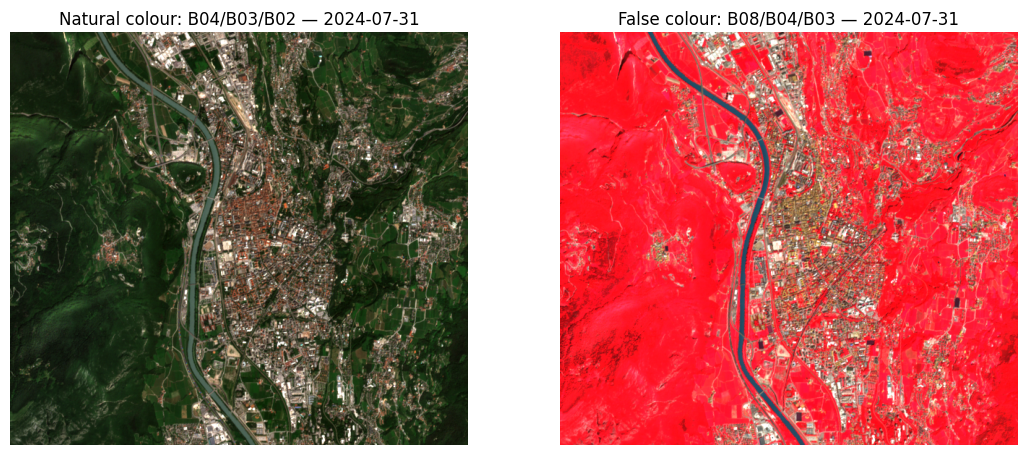

In [20]:
quantification = calibration["quantification_value"]
reflectance = {
    band: (values.filled(np.nan) + calibration["offset_dn"][band]) / quantification
    for band, values in bands.items()
}
rgb_composite = np.dstack([reflectance[b] for b in ["B04", "B03", "B02"]])
false_composite = np.dstack([reflectance[b] for b in ["B08", "B04", "B03"]])
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, array, title in zip(axes, [rgb_composite, false_composite],
                          ["Natural colour: B04/B03/B02", "False colour: B08/B04/B03"]):
    ax.imshow(np.nan_to_num(np.clip(array / 0.3, 0, 1), nan=0))
    ax.set_title(title + f" — {SENTINEL_DATE}")
    ax.set_axis_off()
plt.show()

## 11. Which pixels should we trust for the next calculation?

Cloud, shadow and missing measurements can produce numbers without answering our vegetation question.

Inspect the SCL categories before choosing a mask. We retain vegetation (4), non-vegetated surfaces (5) and water (6) for this conservative teaching example. Other categories are excluded; this choice is useful but not perfect ground truth.

SCL is categorical and has a different grid. Use **nearest-neighbour** to align it: averaging category numbers would invent meaningless classes.

After running the cell, compare retained areas with the optical images. Where have we deliberately refused to calculate?

**Colab AI prompt:** Align SCL to the red-band grid using nearest-neighbour. Show class counts and a mask retaining classes 4,5,6. Explain which pixels are excluded before calculating an index.

,SCL_class,cells_on_optical_grid
0,0,572
1,2,204
2,4,272952
3,5,86200
4,6,2608
5,7,112


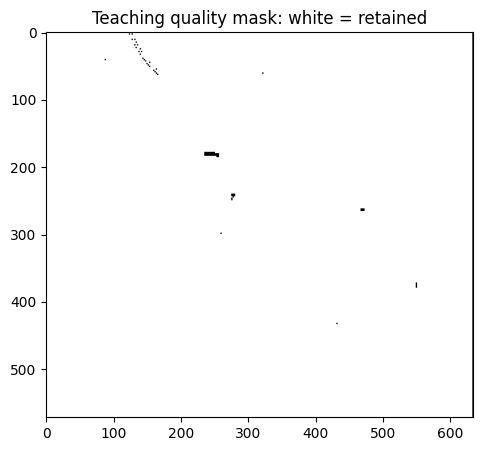

In [21]:
scl = np.zeros((optical_profile["height"], optical_profile["width"]), dtype="uint8")
with rasterio.open(YEAR_DATA / "s2_SCL.tif") as src:
    reproject(source=rasterio.band(src, 1), destination=scl,
              src_transform=src.transform, src_crs=src.crs,
              dst_transform=optical_profile["transform"], dst_crs=optical_profile["crs"],
              src_nodata=0, dst_nodata=0, resampling=Resampling.nearest)
classes, counts = np.unique(scl, return_counts=True)
display(pd.DataFrame({"SCL_class": classes, "cells_on_optical_grid": counts}))
quality_mask = np.isin(scl, [4, 5, 6])
plt.figure(figsize=(7, 5))
plt.imshow(quality_mask, cmap="gray", vmin=0, vmax=1)
plt.title("Teaching quality mask: white = retained")
plt.show()

## 12. Describe the vegetation signal with NDVI

The visitor's question about green patches becomes a measurable spectral question. Vegetation often absorbs red light and reflects strongly in near infrared. NDVI summarises that contrast:

**NDVI = (NIR − red) / (NIR + red)**

Use calibrated reflectance and our quality mask. Missing pixels stay missing; a zero value would be an actual index value.

Compare the map and histogram with the two compositions. A high NDVI does not identify a species, public access, biodiversity or the health of an individual tree.

**Colab AI prompt:** Calculate NDVI from calibrated B08/B04 for valid quality classes and a positive denominator. Plot -1 to 1, inspect its distribution and retained fraction, then relate it to the mapped city below the viewpoint.

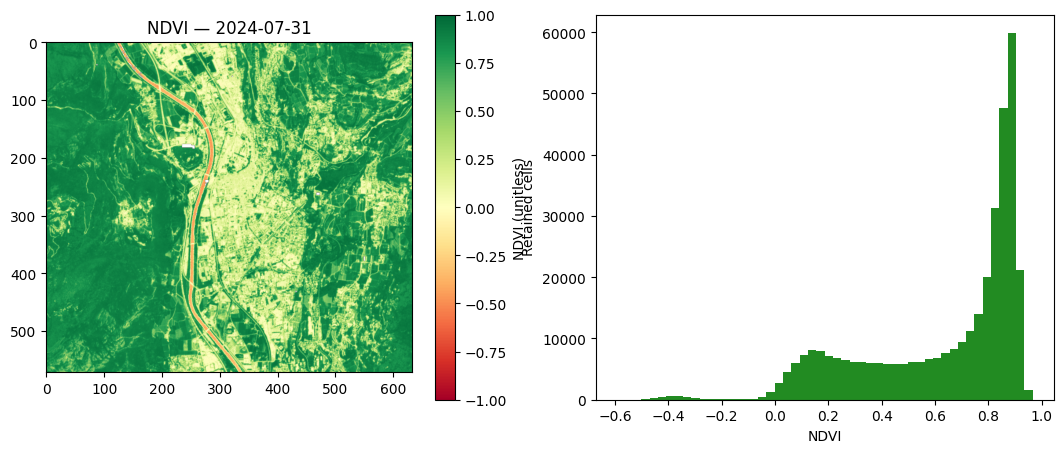

Retained fraction: 0.9975513445544991
NDVI percentiles: [0.09159224 0.78057158 0.90763575]


In [22]:
nir = reflectance["B08"]
red = reflectance["B04"]
denominator = nir + red
valid_ndvi = quality_mask & np.isfinite(nir) & np.isfinite(red) & (denominator > 0)
ndvi = np.full(red.shape, np.nan, dtype="float32")
np.divide(nir - red, denominator, out=ndvi, where=valid_ndvi)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot = axes[0].imshow(np.ma.masked_invalid(ndvi), cmap="RdYlGn", vmin=-1, vmax=1)
axes[0].set_title(f"NDVI — {SENTINEL_DATE}")
fig.colorbar(plot, ax=axes[0], label="NDVI (unitless)")
axes[1].hist(ndvi[np.isfinite(ndvi)], bins=50, color="forestgreen")
axes[1].set_xlabel("NDVI"); axes[1].set_ylabel("Retained cells")
plt.show()
print("Retained fraction:", np.isfinite(ndvi).mean())
print("NDVI percentiles:", np.nanpercentile(ndvi, [5, 50, 95]))

## 13. What would we hand to someone else?

A coloured map communicates the pattern. A numeric GeoTIFF lets another analyst inspect or reuse the index.

Save the actual NDVI values with their original optical grid and explicit NoData. Include the acquisition date and masking choice in its description. The file should explain which observation and calculation produced it.

**Colab AI prompt:** Export NDVI as a float32 GeoTIFF on the optical grid with -9999 as NoData. Add a band description identifying B08/B04 and the retained SCL classes. Do not export the display colours as analytical values.

In [23]:
ndvi_path = YEAR_DATA / "ndvi.tif"
profile = optical_profile.copy()
profile.update(dtype="float32", count=1, nodata=-9999, compress="deflate")
with rasterio.open(ndvi_path, "w", **profile) as dst:
    dst.write(np.where(np.isfinite(ndvi), ndvi, -9999).astype("float32"), 1)
    dst.set_band_description(1, "NDVI; Sentinel-2 B08/B04; SCL classes 4,5,6 retained")
print(ndvi_path)

data/raster_2024_2026/2024/ndvi.tif



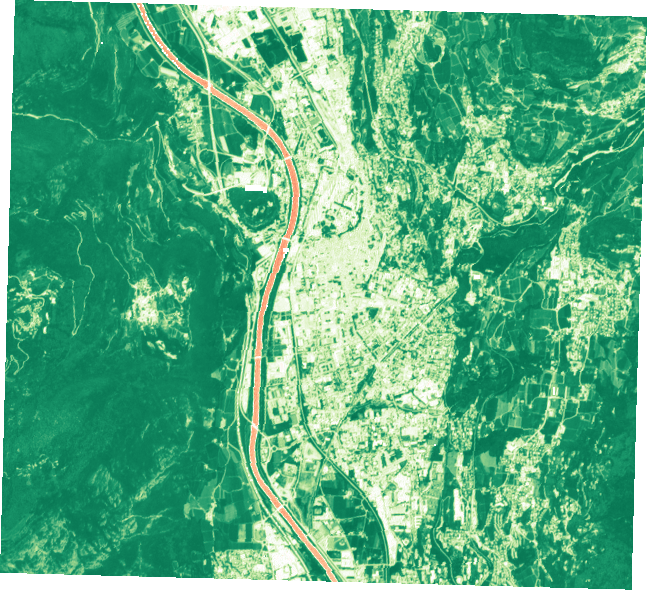

In [24]:
ndvi_map = add_raster_on_osm(ndvi_path, f"NDVI {SENTINEL_DATE}", "RdYlGn", -1, 1,
                              f"NDVI (unitless) — {SENTINEL_DATE}")
folium.Marker([observer_lat, observer_lon], tooltip="Sardagna cable-car arrival").add_to(ndvi_map)
display(ndvi_map)

### Would those green areas be comfortable places to walk?

Try changing the NDVI threshold from 0.3 to 0.5. The indicated area changes because we changed a rule, not because the city changed.

We can describe a vegetation signal, but the visitor might now ask about shade or heat in the city below. NDVI alone does not measure time-specific shade, access or air temperature. Near infrared is reflected solar energy here, not a thermal measurement.

That leads us to another source and another physical quantity.

# Part C · What can we say about the city's hot surfaces?

The visitor looks down towards the city and asks whether the open, built-up areas are hotter than the greener surroundings. Which part of that question can a thermal sensor address?

**Land surface temperature (LST)** is the radiometric temperature of the surface seen by the sensor. It is not the air temperature the visitor would read on a thermometer and is not a complete measure of personal thermal comfort.

Sentinel-2 has no thermal band. Copernicus Sentinel-3 SLSTR L2 LST offers roughly 1 km sampling for a regional picture. A small street or park is not an independent thermal pixel at that scale.

For this exercise we use **NASA/USGS Landsat Collection 2 Level-2 surface temperature**. The product is supplied on a 30 m grid, while Landsat 8/9 thermal native sampling is 100 m. A smaller output cell does not create finer independent observations.

Our selected optical/thermal pairs share a calendar date in each year, but retain distinct acquisition times, spatial support and uncertainties. They are three summer snapshots, not the temperature of today's panorama.

[Sentinel-3 LST](https://dataspace.copernicus.eu/data-collections/copernicus-sentinel-missions/sentinel-3) · [USGS surface temperature](https://www.usgs.gov/landsat-missions/landsat-collection-2-surface-temperature).

## 14. Read the label before reading the temperature

A thermal asset might contain stored digital numbers, brightness temperature or a derived surface-temperature product. These are not interchangeable.

Open this scene's description and inspect the `lwir11` asset metadata. The asset name alone is not an explanation of its physical meaning. Find the scale, offset and missing-data value. Then download temperature and QA together.

The scene may look suitable from its catalogue summary. We will test that assumption on our Trento window next.

**Colab AI prompt:** Read landsat_item.json from the selected year folder. Inspect lwir11 raster metadata and acquisition time, then download landsat_lwir11.tif and landsat_qa_pixel.tif directly from the same GitHub folder. Identify which stored values need scaling.

In [25]:
metadata_path = YEAR_DATA / "landsat_item.json"
if not metadata_path.exists():
    response = requests.get(YEAR_BASE_URL + metadata_path.name, timeout=60)
    response.raise_for_status()
    metadata_path.write_bytes(response.content)
landsat_item = json.loads(metadata_path.read_text())
assert landsat_item["properties"]["datetime"].startswith(str(YEAR))
print("Scene:", landsat_item["id"])
print("Acquisition UTC:", landsat_item["properties"]["datetime"])
# Check the asset titles: QA_PIXEL is a cloud/condition bit mask; ST_QA is uncertainty.
for asset in ["lwir11", "qa_pixel", "qa"]:
    print(asset, landsat_item["assets"][asset]["title"])
    display(landsat_item["assets"][asset].get("raster:bands"))
for filename in ["landsat_lwir11.tif", "landsat_qa_pixel.tif", "landsat_st_qa.tif"]:
    path = YEAR_DATA / filename
    if not path.exists():
        response = requests.get(YEAR_BASE_URL + filename, timeout=60)
        response.raise_for_status()
        path.write_bytes(response.content)
    print("Using:", path)

Scene: LC09_L2SP_193028_20240731_02_T1
Acquisition UTC: 2024-07-31T10:04:01.919850Z
lwir11 Surface Temperature Band


[{'unit': 'kelvin',
  'scale': 0.00341802,
  'nodata': 0,
  'offset': 149,
  'data_type': 'uint16',
  'spatial_resolution': 30}]

qa_pixel Pixel Quality Assessment Band


[{'unit': 'bit index',
  'nodata': 1,
  'data_type': 'uint16',
  'spatial_resolution': 30}]

qa Surface Temperature Quality Assessment Band


[{'unit': 'kelvin',
  'scale': 0.01,
  'nodata': -9999,
  'data_type': 'int16',
  'spatial_resolution': 30}]

Using: data/raster_2024_2026/2024/landsat_lwir11.tif
Using: data/raster_2024_2026/2024/landsat_qa_pixel.tif
Using: data/raster_2024_2026/2024/landsat_st_qa.tif


## 15. Where do we actually have a usable measurement?

Do not start by stretching the temperature map until it looks convincing. Inspect the quality flags and how much of our study area survives.

For the selected Landsat 8/9 products, QA_PIXEL bits 0–5 identify fill, dilated cloud, cirrus, cloud, shadow and snow. We exclude them and DN=0 for the teaching mask. Other retrieval uncertainties still remain.

USGS specifies **Kelvin = DN × 0.00341802 + 149**. Subtract 273.15 for Celsius. We read scale and offset from the metadata rather than assuming the stored integer already means degrees.

**Stop after the cell:** what fraction of Trento has a retained value? Is it enough to describe the city? The scene-wide cloud percentage cannot answer that local question.

**Colab AI prompt:** Check that temperature and QA grids match. Exclude DN=0 and QA bits 0-5. Read scale and offset from metadata, convert to Celsius and report the retained fraction before plotting. Explain why low local coverage limits the conclusion.

In [26]:
with rasterio.open(YEAR_DATA / "landsat_lwir11.tif") as src:
    temperature_dn = src.read(1)
    temperature_profile = src.profile.copy()
with rasterio.open(YEAR_DATA / "landsat_qa_pixel.tif") as src:
    assert src.crs == temperature_profile["crs"]
    assert src.transform == temperature_profile["transform"]
    assert src.shape == temperature_dn.shape
    qa_pixel = src.read(1)

# Bits 0 through 5 are excluded; this does not remove every possible retrieval error.
clear = (qa_pixel & 0b111111) == 0
valid_temperature = clear & (temperature_dn != 0)
thermal_metadata = landsat_item["assets"]["lwir11"]["raster:bands"][0]
scale = thermal_metadata["scale"]
offset = thermal_metadata["offset"]
print("Scale and offset:", scale, offset)
lst_celsius = temperature_dn.astype("float32") * scale + offset - 273.15
lst_celsius[~valid_temperature] = np.nan
print("Valid fraction:", np.isfinite(lst_celsius).mean())
print("Celsius percentiles:", np.nanpercentile(lst_celsius, [5, 50, 95]))
coverage = np.isfinite(lst_celsius).mean()
if coverage < 0.5:
    print(f"Only {coverage:.1%} of this local window passes our mask.")
    print("Inspect the retained pixels, but select another acquisition before describing city-wide temperature patterns.")

Scale and offset: 0.00341802 149
Valid fraction: 1.0
Celsius percentiles: [27.02218628 35.36898804 45.17871094]


### Read the coverage before the colours

Inspect the retained fraction and the mask. Missing pixels are not cold surfaces. The selection aimed for high local coverage, but quality must still be checked for every acquisition.

ST_QA is a separate uncertainty estimate, supplied in hundredths of kelvin in this product. It can help assess confidence; it is not the cloud bit mask. The conversion below illustrates its meaning without inventing a new quality threshold.


In [27]:
with rasterio.open(YEAR_DATA / "landsat_st_qa.tif") as src:
    st_qa = src.read(1, masked=True).astype("float32")
uncertainty_metadata = landsat_item["assets"]["qa"]["raster:bands"][0]
uncertainty_k = st_qa.filled(np.nan) * uncertainty_metadata["scale"]
uncertainty_k[~valid_temperature] = np.nan
print("ST_QA uncertainty, kelvin — 5th/50th/95th percentiles:",
      np.nanpercentile(uncertainty_k, [5, 50, 95]))

ST_QA uncertainty, kelvin — 5th/50th/95th percentiles: [2.25       2.63999987 2.83999991]


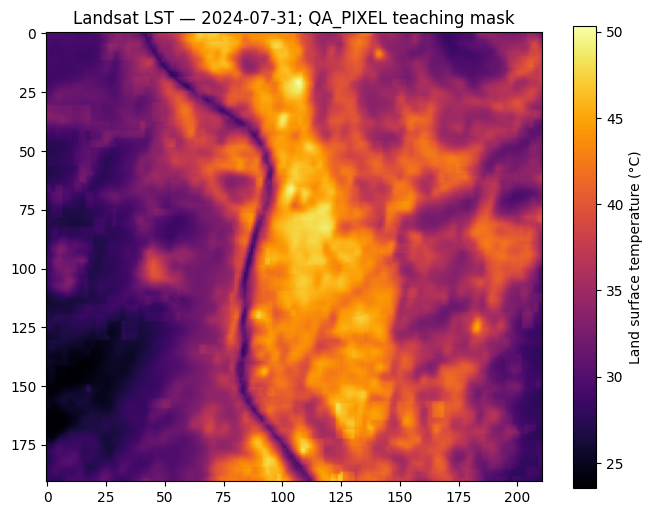

In [28]:
plt.figure(figsize=(8, 6))
plt.imshow(np.ma.masked_invalid(lst_celsius), cmap="inferno")
plt.colorbar(label="Land surface temperature (°C)")
plt.title(f"Landsat LST — {LANDSAT_DATE}; QA_PIXEL teaching mask")
plt.show()
lst_path = YEAR_DATA / "lst_celsius.tif"
profile = temperature_profile.copy()
profile.update(dtype="float32", count=1, nodata=-9999, compress="deflate")
with rasterio.open(lst_path, "w", **profile) as dst:
    dst.write(np.where(np.isfinite(lst_celsius), lst_celsius, -9999).astype("float32"), 1)
    dst.set_band_description(1, "Land surface temperature Celsius; QA bits 0-5 excluded")

## 16. Put the temperature observations back on the city map

Display the Celsius raster over OSM and mark the Sardagna arrival point. The marker helps orient the story; it does not imply that the thermal observation was made from the cable car or at the visitor's eye height.

Use a fixed 15–50 °C colour scale, a date and transparent NoData. The grayscale basemap provides place context while the analytical overlay stays in colour. The 40% opacity is a display choice, not a modification of the measured temperature.

Reprojection to Web Mercator prepares this web rendering. The numeric GeoTIFF remains the analytical output.

**Colab AI prompt:** Show the saved LST raster over grayscale HOT OSM with the supplied arrival point, fixed Celsius legend and date. Preserve missing pixels as transparent and distinguish surface temperature from air temperature.


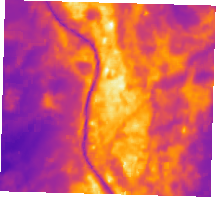

In [29]:
lst_map = add_raster_on_osm(lst_path, f"LST {LANDSAT_DATE}", "inferno", 15, 50,
                             f"Land surface temperature (°C) — {LANDSAT_DATE}")
folium.Marker([observer_lat, observer_lon], tooltip="Sardagna cable-car arrival").add_to(lst_map)
display(lst_map)

## Answer the question at the cable-car arrival

Return to the visitor's opening question: **“What can I see from here?”** Build a short explanation using the results, not just the attractiveness of a map.

| Part of the answer | Evidence used | Limit to explain |
|---|---|---|
| Which surface areas could be in view? | Terrain mosaic, arrival coordinates, observer height, viewshed | Modelled surface and finite extent; actual obstacles and landmark heights need checking |
| Where does the city show a vegetation signal? | Calibrated Sentinel-2 reflectance, quality mask, NDVI | Acquisition date and spectral support; not species, access or today's view |
| What surface temperatures were observed? | Landsat Level-2 ST, QA_PIXEL and ST_QA | Surface temperature, resolution and retrieval uncertainty; not air temperature |
| What differs across the three observations? | Fixed-scale maps for 2024,2025,2026 | Snapshots with different conditions, not a climatic trend or causal test |

**Exercise:** use the OSM context to choose a named place in the landscape. Explain which part of your answer comes from the basemap, the elevation model, satellite measurements or external local knowledge. What would you check on site before turning this into a visitor information panel?

A useful explanation can tell the visitor something concrete while making the boundaries of the evidence clear.

## Revisit the same city in 2024, 2025 and 2026

Keep the Sardagna arrival point as our orientation marker while selecting a year on the two maps. The saved derived rasters use the same calibration and masking recipe demonstrated above. Change YEAR and rerun the satellite sections to reproduce another pair yourself.

Each variable has its own fixed legend across years. Select one acquisition at a time rather than mixing overlapping colours. These maps compare dated observations geographically; numerical pixel-change analysis would additionally need matched grids and comparable valid spatial support.

NDVI: select an acquisition year



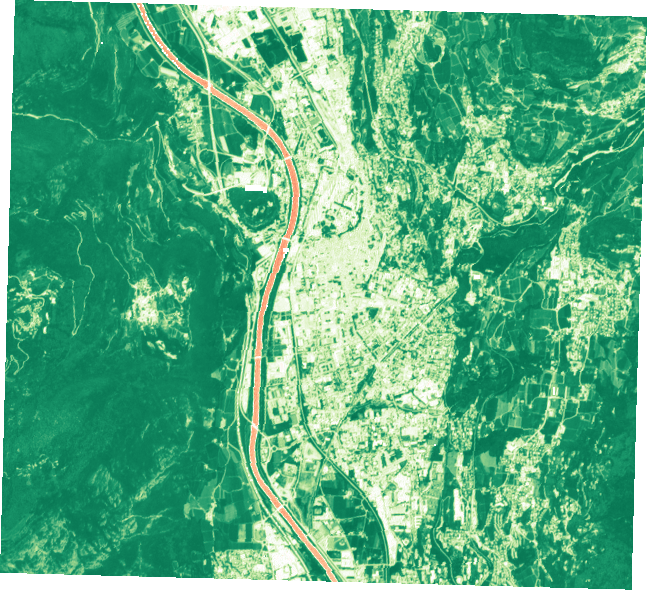
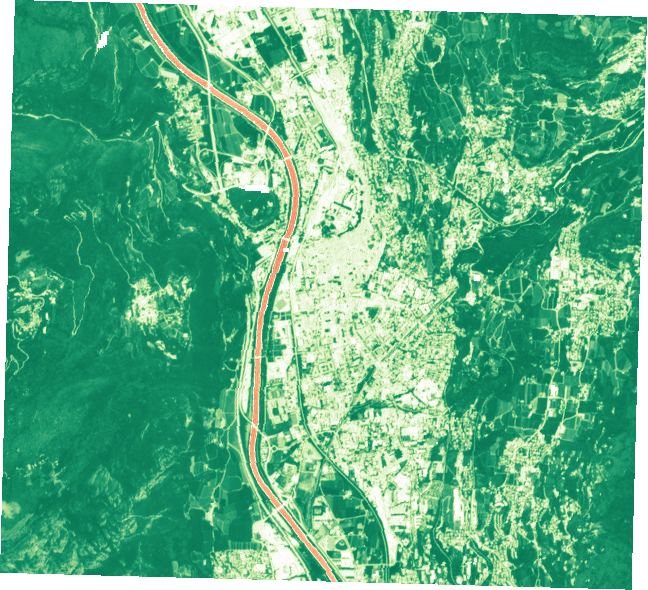
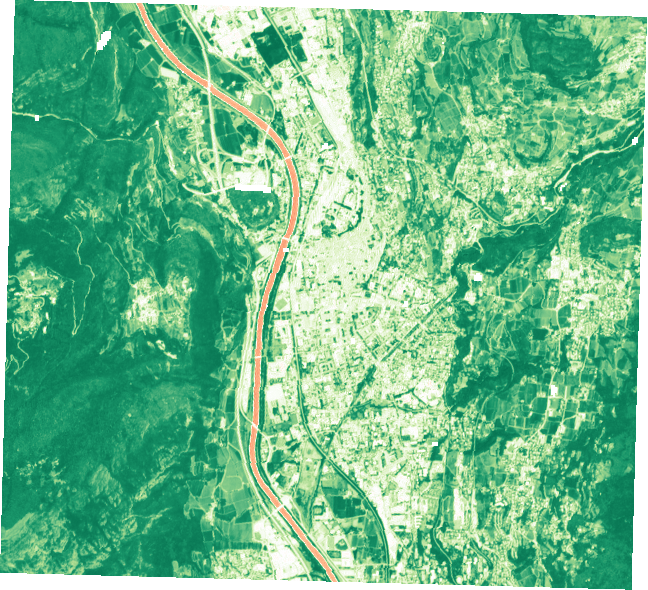

Surface temperature: select an acquisition year



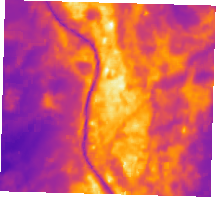
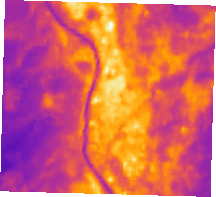
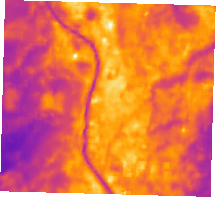

In [30]:
ndvi_year_map = None
lst_year_map = None
for record in annual_catalog["records"]:
    year = record["year"]
    folder = DATA / record["files_folder"]
    folder.mkdir(parents=True, exist_ok=True)
    # These files are supplied as derived outputs; the earlier cells show how to reproduce them.
    for filename in ["ndvi.tif", "lst_celsius.tif"]:
        path = folder / filename
        if not path.exists():
            url = DATA_BASE_URL + record["files_folder"] + "/" + filename
            response = requests.get(url, timeout=60)
            response.raise_for_status()
            path.write_bytes(response.content)
    ndvi_year_map = add_raster_on_osm(
        folder / "ndvi.tif", f"{year}: {record['sentinel_date']}", "RdYlGn", -1, 1,
        "NDVI — fixed scale for 2024–2026", m=ndvi_year_map,
        show_layer=(year == 2024), year_choice=True)
    lst_year_map = add_raster_on_osm(
        folder / "lst_celsius.tif", f"{year}: {record['landsat_date']}", "inferno", 15, 50,
        "Land surface temperature (°C) — fixed scale", m=lst_year_map,
        show_layer=(year == 2024), year_choice=True)
folium.Marker([observer_lat, observer_lon], tooltip="Sardagna cable-car arrival").add_to(ndvi_year_map)
folium.Marker([observer_lat, observer_lon], tooltip="Sardagna cable-car arrival").add_to(lst_year_map)
folium.LayerControl(collapsed=False).add_to(ndvi_year_map)
folium.LayerControl(collapsed=False).add_to(lst_year_map)
print("NDVI: select an acquisition year")
display(ndvi_year_map)
print("Surface temperature: select an acquisition year")
display(lst_year_map)
ndvi_year_map.save("trento_ndvi_2024_2026_osm.html")
lst_year_map.save("trento_lst_2024_2026_osm.html")